In [1]:
#!/usr/bin/env python
from uproot_methods import TVector2Array, TLorentzVectorArray
from optparse import OptionParser
from coffea.jetmet_tools import FactorizedJetCorrector, JetCorrectionUncertainty, JetTransformer, JetResolution, JetResolutionScaleFactor
from coffea.util import load, save
from coffea import hist, processor
from coffea.arrays import Initialize
import lz4.frame as lz4f
import cloudpickle
import json
import pprint
import numpy as np
import math
import awkward
np.seterr(divide='ignore', invalid='ignore', over='ignore')
import time

class AnalysisProcessor(processor.ProcessorABC):

    lumis = {  # Values from https://twiki.cern.ch/twiki/bin/viewauth/CMS/PdmVAnalysisSummaryTable
        '2016': 35.92,
        '2017': 40.66,
        '2018': 59.74
    }

    met_filter_flags = {

        '2016': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter'
                 ],

        '2017': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'ecalBadCalibFilter'
                 ],

        '2018': ['goodVertices',
                 'globalSuperTightHalo2016Filter',
                 'HBHENoiseFilter',
                 'HBHENoiseIsoFilter',
                 'EcalDeadCellTriggerPrimitiveFilter',
                 'BadPFMuonFilter',
                 'ecalBadCalibFilter'
                 ]
    }

    def __init__(self, year, xsec, corrections, ids, common):

        self._columns = """
        CaloMET_pt
        CaloMET_phi
        Electron_charge
        Electron_cutBased
        Electron_dxy
        Electron_dz
        Electron_eta
        Electron_mass
        Electron_phi
        Electron_pt
        Flag_BadPFMuonFilter
        Flag_EcalDeadCellTriggerPrimitiveFilter
        Flag_HBHENoiseFilter
        Flag_HBHENoiseIsoFilter
        Flag_globalSuperTightHalo2016Filter
        Flag_goodVertices
        GenPart_eta
        GenPart_genPartIdxMother
        GenPart_pdgId
        GenPart_phi
        GenPart_pt
        GenPart_statusFlags
        HLT_Ele115_CaloIdVT_GsfTrkIdT
        HLT_Ele32_WPTight_Gsf
        HLT_PFMETNoMu120_PFMHTNoMu120_IDTight
        HLT_PFMETNoMu120_PFMHTNoMu120_IDTight_PFHT60
        HLT_Photon200
        Jet_btagDeepB
        Jet_btagDeepFlavB
        Jet_chEmEF
        Jet_chHEF
        Jet_eta
        Jet_hadronFlavour
        Jet_jetId
        Jet_mass
        Jet_neEmEF
        Jet_neHEF
        Jet_phi
        Jet_pt
        Jet_rawFactor
        MET_phi
        MET_pt
        Muon_charge
        Muon_eta
        Muon_looseId
        Muon_mass
        Muon_pfRelIso04_all
        Muon_phi
        Muon_pt
        Muon_tightId
        PV_npvs
        Photon_eta
        Photon_phi
        Photon_pt
        Tau_eta
        Tau_idDecayMode
        Tau_idDecayModeOldDMs
        Tau_idMVAoldDM2017v2
        Tau_phi
        Tau_pt
        fixedGridRhoFastjetAll
        genWeight
        nElectron
        nGenPart
        nJet
        nMuon
        nPhoton
        nTau
        """.split()

        self._year = year

        self._lumi = 1000.*float(AnalysisProcessor.lumis[year])

        self._xsec = xsec

        self._samples = {
            'sre':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleElectron','SinglePhoton','EGamma'),
            'srm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon'),
            'ttbare':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleElectron','SinglePhoton','EGamma'),
            'ttbarm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon'),
            'wjete':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD', 'SingleElectron','SinglePhoton','EGamma'),
            'wjetm':('WJets','DY','TT','ST','WW','WZ','ZZ','QCD','SingleMuon'),
        }

        self._gentype_map = {
            'xbb':      1,
            'tbcq':     2,
            'tbqq':     3,
            'zcc':      4,
            'wcq':      5,
            'vqq':      6,
            'bb':       7,
            'bc':       8,
            'b':        9,
            'cc':     10,
            'c':       11,
            'other':   12
            # 'garbage': 13
        }

        self._ZHbbvsQCDwp = {
            '2016': 0.53,
            '2017': 0.61,
            '2018': 0.65
        }

        self._met_triggers = {
            '2016': [
                'PFMETNoMu90_PFMHTNoMu90_IDTight',
                'PFMETNoMu100_PFMHTNoMu100_IDTight',
                'PFMETNoMu110_PFMHTNoMu110_IDTight',
                'PFMETNoMu120_PFMHTNoMu120_IDTight'
            ],
            '2017': [
                'PFMETNoMu120_PFMHTNoMu120_IDTight_PFHT60',
                'PFMETNoMu120_PFMHTNoMu120_IDTight'
            ],
            '2018': [
                'PFMETNoMu120_PFMHTNoMu120_IDTight_PFHT60',
                'PFMETNoMu120_PFMHTNoMu120_IDTight'
            ]
        }

        self._singlephoton_triggers = {
            '2016': [
                'Photon175',
                'Photon165_HE10'
            ],
            '2017': [
                'Photon200'
            ],
            '2018': [
                'Photon200'
            ]
        }

        self._singleelectron_triggers = {  # 2017 and 2018 from monojet, applying dedicated trigger weights
            '2016': [
                'Ele27_WPTight_Gsf',
#                 'Ele105_CaloIdVT_GsfTrkIdT'
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Ele50_CaloIdVT_GsfTrkIdT_PFJet165',
            ],
            '2017': [
                'Ele35_WPTight_Gsf',
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Photon200',
                'Ele50_CaloIdVT_GsfTrkIdT_PFJet165',
            ],
            '2018': [
                'Ele32_WPTight_Gsf',
                'Ele115_CaloIdVT_GsfTrkIdT',
                'Photon200',
#                 'Ele50_CaloIdVT_GsfTrkIdT_PFJet165'
            ]
        }
        self._singlemuon_triggers = {
            '2016': [
                'IsoMu24',
                'IsoTkMu24',
                'Mu50',
                'TkMu50'

            ],
            '2017':
                [
                'IsoMu27',
                'Mu50',
                'OldMu100',
                'TkMu100'
            ],
            '2018':
                [
                'IsoMu24',
                'Mu50',
                'OldMu100',
                'TkMu100'
            ]
        }

        self._jec = {

            '2016': [
                'Summer16_07Aug2017_V11_MC_L1FastJet_AK4PFPuppi',
                'Summer16_07Aug2017_V11_MC_L2L3Residual_AK4PFPuppi',
                'Summer16_07Aug2017_V11_MC_L2Relative_AK4PFPuppi',
                'Summer16_07Aug2017_V11_MC_L2Residual_AK4PFPuppi',
                'Summer16_07Aug2017_V11_MC_L3Absolute_AK4PFPuppi'
            ],

            '2017': [
                'Fall17_17Nov2017_V32_MC_L1FastJet_AK4PFPuppi',
                'Fall17_17Nov2017_V32_MC_L2L3Residual_AK4PFPuppi',
                'Fall17_17Nov2017_V32_MC_L2Relative_AK4PFPuppi',
                'Fall17_17Nov2017_V32_MC_L2Residual_AK4PFPuppi',
                'Fall17_17Nov2017_V32_MC_L3Absolute_AK4PFPuppi'
            ],

            '2018': [
                'Autumn18_V19_MC_L1FastJet_AK4PFPuppi',
                'Autumn18_V19_MC_L2L3Residual_AK4PFPuppi',
                'Autumn18_V19_MC_L2Relative_AK4PFPuppi',  # currently broken
                'Autumn18_V19_MC_L2Residual_AK4PFPuppi',
                'Autumn18_V19_MC_L3Absolute_AK4PFPuppi'
            ]
        }

        self._junc = {

            '2016': [
                'Summer16_07Aug2017_V11_MC_Uncertainty_AK4PFPuppi'
            ],

            '2017': [
                'Fall17_17Nov2017_V32_MC_Uncertainty_AK4PFPuppi'
            ],

            '2018': [
                'Autumn18_V19_MC_Uncertainty_AK4PFPuppi'
            ]
        }

        self._jr = {

            '2016': [
                'Summer16_25nsV1b_MC_PtResolution_AK4PFPuppi'
            ],

            '2017': [
                'Fall17_V3b_MC_PtResolution_AK4PFPuppi'
            ],

            '2018': [
                'Autumn18_V7b_MC_PtResolution_AK4PFPuppi'
            ]
        }

        self._jersf = {

            '2016': [
                'Summer16_25nsV1b_MC_SF_AK4PFPuppi'
            ],

            '2017': [
                'Fall17_V3b_MC_SF_AK4PFPuppi'
            ],

            '2018': [
                'Autumn18_V7b_MC_SF_AK4PFPuppi'
            ]
        }

        self._corrections = corrections
        self._ids = ids
        self._common = common

        self._accumulator = processor.dict_accumulator({
            'sumw': hist.Hist(
                'sumw',
                hist.Cat('dataset', 'Dataset'),
                hist.Bin('sumw', 'Weight value', [0.])
            ),
            'mT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('mT', '$m_{T}$ [GeV]', 20, 0, 600)),
            'eT_miss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('eT_miss', '$E^T_{miss}$[GeV]', 20, 0, 600)),

            'ele_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('ele_pT', 'Tight electron $p_{T}$ [GeV]', 10, 0, 200)),

            'mu_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('mu_pT', 'Tight Muon $p_{T}$ [GeV]', 10, 0, 200)),

            'jet_pT': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('jet_pT', 'Leading $AK4 Jet p_{T}$ [GeV]',
                         [30.0, 60.0, 90.0, 120.0, 150.0, 180.0, 210.0, 250.0, 280.0, 310.0, 340.0, 370.0, 400.0, 430.0, 470.0, 510.0, 550.0, 590.0, 640.0, 690.0, 740.0, 790.0, 840.0, 900.0, 960.0, 1020.0, 1090.0, 1160.0, 1250.0])),
            'jet_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('jet_eta','AK4 Leading Jet Eta',35,-3.5,3.5)
            ),
            'jet_phi': hist.Hist(
                'Events', 
                hist.Cat('dataset', 'Dataset'), 
                hist.Cat('region', 'Region'), 
                hist.Bin('jet_phi','AK4 Leading Jet Phi',35,-3.5,3.5)
            ),
            'dphi_e_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('dphi_e_etmiss', '$\Delta\phi (e, E^T_{miss} )$', 30, 0, 3.5)),
            'dphi_mu_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('dphi_mu_etmiss',
                         '$\Delta\phi (\mu, E^T_{miss} )$', 30, 0, 3.5)),
            'ndflvL': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('ndflvL', 'AK4 Number of deepFlavor Loose Jets', 6, -0.5, 5.5)),
            'ndflvM': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('ndflvM', 'AK4 Number of deepFlavor Medium Jets', 6, -0.5, 5.5)),
            'njets': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('njets', 'AK4 Number of Jets', 7, -0.5, 6.5)),

            'ndcsvM': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('ndcsvM', 'AK4 Number of deepCSV Medium Jets', 6, -0.5, 5.5)),
            'dphi_Met_LJ': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('dphi_Met_LJ', '$\Delta \Phi (E^T_{miss}, Leading Jet)$', 30, 0, 3.5)),
            'dr_e_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('dr_e_lj', '$\Delta r (Leading e, Leading Jet)$', 30, 0, 5.0)),
            'dr_mu_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('dr_mu_lj', '$\Delta r (Leading \mu, Leading Jet)$', 30, 0, 5.0)),
            'ele_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('ele_eta', 'Leading Electron Eta', 48, -2.4, 2.4)),
            'mu_eta': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('mu_eta', 'Leading Muon Eta', 48, -2.4, 2.4)),
            'ele_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('ele_phi', 'Leading Electron Phi', 64, -3.2, 3.2)),
            'metphi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('metphi','MET phi',35,-3.5,3.5)),
            'mu_phi': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Bin('mu_phi', 'Leading Muon Phi', 64, -3.2, 3.2)),
            'template_mt_dphi_met_lj': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mT', '$m_{T}$ [GeV]', 20, 0, 600),
                hist.Bin('dphi_Met_LJ', '$\Delta \Phi (E^T_{miss}, leading Jet)$', 30, 0, 3.5),
#                 hist.Bin('dphi_lep_etmiss', '$\Delta\phi (lepton, E^T_{miss} )$', 30, 0, 3.5),
#                 hist.Bin('eT_miss', '$E^T_{miss}$[GeV]', 20, 0, 600)
            ),
            'template_mt_dphi_lep_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
                hist.Bin('mT', '$m_{T}$ [GeV]', 20, 0, 600),
#                 hist.Bin('dphi_Met_LJ', '$\Delta \Phi (E^T_{miss}, leading Jet)$', 30, 0, 3.5),
                hist.Bin('dphi_lep_etmiss', '$\Delta\phi (lepton, E^T_{miss} )$', 30, 0, 3.5),
#                 hist.Bin('eT_miss', '$E^T_{miss}$[GeV]', 20, 0, 600)
            ),
            'template_etmiss_dphi_lep_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
#                 hist.Bin('mT', '$m_{T}$ [GeV]', 20, 0, 600),
#                 hist.Bin('dphi_Met_LJ', '$\Delta \Phi (E^T_{miss}, leading Jet)$', 30, 0, 3.5),
                hist.Bin('dphi_lep_etmiss', '$\Delta\phi (lepton, E^T_{miss} )$', 30, 0, 3.5),
                hist.Bin('eT_miss', '$E^T_{miss}$[GeV]', 20, 0, 600)
            ),
            'template_lep_eta_dphi_lep_etmiss': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                hist.Cat('systematic', 'Systematic'),
#                 hist.Bin('mT', '$m_{T}$ [GeV]', 20, 0, 600),
#                 hist.Bin('dphi_Met_LJ', '$\Delta \Phi (E^T_{miss}, leading Jet)$', 30, 0, 3.5),
                hist.Bin('dphi_lep_etmiss', '$\Delta\phi (lepton, E^T_{miss} )$', 30, 0, 3.5),
                hist.Bin('lep_eta', 'Leading Lepton Eta', 48, -2.4, 2.4)
            ),
            'cutflow': hist.Hist(
                'Events',
                hist.Cat('dataset', 'Dataset'),
                hist.Cat('region', 'Region'),
                #hist.Bin('cut', 'Cut index', 11, 0, 11),
                hist.Bin('cut', 'Cut index', [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]),
            ),
        })

    @property
    def accumulator(self):
        return self._accumulator

    @property
    def columns(self):
        return self._columns

    def process(self, events):

        dataset = events.metadata['dataset']
#         print(dataset)
#         print(self._lumi)
        selected_regions = []
        for region, samples in self._samples.items():
            for sample in samples:
                if sample not in dataset:
                    continue
                selected_regions.append(region)
#         print(events.columns)
#         import sys
#         sys.exit(0)
        isData = 'genWeight' not in events.columns
        selection = processor.PackedSelection()
        hout = self.accumulator.identity()

        ###
        # Getting corrections, ids from .coffea files
        ###

        get_msd_weight = self._corrections['get_msd_weight']
        get_ttbar_weight = self._corrections['get_ttbar_weight']
        get_nnlo_nlo_weight = self._corrections['get_nnlo_nlo_weight'][self._year]
        get_nlo_qcd_weight = self._corrections['get_nlo_qcd_weight'][self._year]
        get_nlo_ewk_weight = self._corrections['get_nlo_ewk_weight'][self._year]
        get_pu_weight = self._corrections['get_pu_weight'][self._year]
        get_met_trig_weight = self._corrections['get_met_trig_weight'][self._year]
        get_met_zmm_trig_weight = self._corrections['get_met_zmm_trig_weight'][self._year]
        get_ele_trig_weight = self._corrections['get_ele_trig_weight'][self._year]
        get_mu_trig_weight = self._corrections['get_mu_trig_weight'][self._year]
        get_pho_trig_weight = self._corrections['get_pho_trig_weight'][self._year]
        get_ele_loose_id_sf = self._corrections['get_ele_loose_id_sf'][self._year]
        get_ele_tight_id_sf = self._corrections['get_ele_tight_id_sf'][self._year]
        get_pho_tight_id_sf = self._corrections['get_pho_tight_id_sf'][self._year]
        get_pho_csev_sf = self._corrections['get_pho_csev_sf'][self._year]
        get_mu_tight_id_sf = self._corrections['get_mu_tight_id_sf'][self._year]
        get_mu_loose_id_sf = self._corrections['get_mu_loose_id_sf'][self._year]
        get_ele_reco_sf = self._corrections['get_ele_reco_sf'][self._year]
        get_ele_reco_lowet_sf = self._corrections['get_ele_reco_lowet_sf']
        get_mu_tight_iso_sf = self._corrections['get_mu_tight_iso_sf'][self._year]
        get_mu_loose_iso_sf = self._corrections['get_mu_loose_iso_sf'][self._year]
        get_ecal_bad_calib = self._corrections['get_ecal_bad_calib']
        get_deepflav_weight = self._corrections['get_btag_weight']['deepflav'][self._year]
        get_deepcsv_weight = self._corrections['get_btag_weight']['deepcsv'][self._year]
        Jetevaluator = self._corrections['Jetevaluator']

        isLooseElectron = self._ids['isLooseElectron']
        isTightElectron = self._ids['isTightElectron']
        isLooseMuon = self._ids['isLooseMuon']
        isTightMuon = self._ids['isTightMuon']
        isLooseTau = self._ids['isLooseTau']
        isLoosePhoton = self._ids['isLoosePhoton']
        isTightPhoton = self._ids['isTightPhoton']
        isGoodJet = self._ids['isGoodJet']
        isHEMJet = self._ids['isHEMJet']

        match = self._common['match']
        # to calculate photon trigger efficiency
        sigmoid = self._common['sigmoid']
        deepflavWPs = self._common['btagWPs']['deepflav'][self._year]
        deepcsvWPs = self._common['btagWPs']['deepcsv'][self._year]

        ###
        # Derive jet corrector for JEC/JER
        ###

        JECcorrector = FactorizedJetCorrector(
            **{name: Jetevaluator[name] for name in self._jec[self._year]})
        JECuncertainties = JetCorrectionUncertainty(
            **{name: Jetevaluator[name] for name in self._junc[self._year]})
        JER = JetResolution(
            **{name: Jetevaluator[name] for name in self._jr[self._year]})
        JERsf = JetResolutionScaleFactor(
            **{name: Jetevaluator[name] for name in self._jersf[self._year]})
        Jet_transformer = JetTransformer(
            jec=JECcorrector, junc=JECuncertainties, jer=JER, jersf=JERsf)

        ###
        # Initialize global quantities (MET ecc.)
        ###

        met = events.MET
#         if self._year == '2017':
#             events.METFixEE2017  # Recommended for 2017
        met['T'] = TVector2Array.from_polar(met.pt, met.phi)
        calomet = events.CaloMET
        puppimet = events.PuppiMET
        puppimet['T'] = TVector2Array.from_polar(puppimet.pt, puppimet.phi)

        ###
        # Initialize physics objects
        ###

        mu = events.Muon
        mu['isloose'] = isLooseMuon(
            mu.pt, mu.eta, mu.pfRelIso04_all, mu.looseId, self._year)
        mu['istight'] = isTightMuon(
            mu.pt, mu.eta, mu.pfRelIso04_all, mu.tightId, self._year)
        mu['T'] = TVector2Array.from_polar(mu.pt, mu.phi)
        mu['p4'] = TLorentzVectorArray.from_ptetaphim(
            mu.pt, mu.eta, mu.phi, mu.mass)
        mu_loose = mu[mu.isloose.astype(np.bool)]
        mu_tight = mu[mu.istight.astype(np.bool)]
        mu_ntot = mu.counts
        mu_nloose = mu_loose.counts
        mu_ntight = mu_tight.counts
        leading_mu = mu[mu.pt.argmax()]
        leading_mu = leading_mu[leading_mu.istight.astype(np.bool)]

        e = events.Electron
        e['isclean'] = ~match(e, mu_loose, 0.3)
        e['isloose'] = isLooseElectron(
            e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, self._year)
        e['istight'] = isTightElectron(
            e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, self._year)
        e['T'] = TVector2Array.from_polar(e.pt, e.phi)
        e['p4'] = TLorentzVectorArray.from_ptetaphim(
            e.pt, e.eta, e.phi, e.mass)
        e_clean = e[e.isclean.astype(np.bool)]
        e_loose = e_clean[e_clean.isloose.astype(np.bool)]
        e_tight = e_clean[e_clean.istight.astype(np.bool)]
        e_ntot = e.counts
        e_nloose = e_loose.counts
        e_ntight = e_tight.counts
        leading_e = e[e.pt.argmax()]
        leading_e = leading_e[leading_e.isclean.astype(np.bool)]
        leading_e = leading_e[leading_e.istight.astype(np.bool)]

        tau = events.Tau
        tau['isclean'] = ~match(tau, mu_loose, 0.4) & ~match(tau, e_loose, 0.4)
        try:
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayMode,tau.idDeepTau2017v2p1VSjet,self._year)
        except:
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeOldDMs,tau.idDeepTau2017v2p1VSjet,self._year)
        else: 
            tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeNewDMs,tau.idDeepTau2017v2p1VSjet,self._year)

        tau_clean = tau[tau.isclean.astype(np.bool)]
        tau_loose = tau_clean[tau_clean.isloose.astype(np.bool)]
        tau_ntot = tau.counts
        tau_nloose = tau_loose.counts

        pho = events.Photon
        pho['isclean'] = ~match(pho, mu_loose, 0.5) & ~match(pho, e_loose, 0.5)
        _id = 'cutBased'
        if self._year == '2016':
            _id = 'cutBased'
        pho['isloose']=isLoosePhoton(pho.pt,pho.eta,pho[_id],self._year)&(pho.electronVeto) #added electron veto flag
        pho['istight']=isTightPhoton(pho.pt,pho[_id],self._year)&(pho.isScEtaEB)&(pho.electronVeto)
        pho['T'] = TVector2Array.from_polar(pho.pt, pho.phi)
        pho_clean = pho[pho.isclean.astype(np.bool)]
        pho_loose = pho_clean[pho_clean.isloose.astype(np.bool)]
        pho_tight = pho_clean[pho_clean.istight.astype(np.bool)]
        pho_ntot = pho.counts
        pho_nloose = pho_loose.counts
        pho_ntight = pho_tight.counts
        leading_pho = pho[pho.pt.argmax()]
        leading_pho = leading_pho[leading_pho.isclean.astype(np.bool)]
        leading_pho = leading_pho[leading_pho.istight.astype(np.bool)]

        j = events.Jet
        j['isgood'] = isGoodJet(j.pt, j.eta, j.jetId, j.puId, j.neHEF, j.chHEF)
        j['isHEM'] = isHEMJet(j.pt, j.eta, j.phi)
        j['isclean'] = ~match(j, e_loose, 0.4) & ~match(
            j, mu_loose, 0.4) & ~match(j, pho_loose, 0.4)
#         print(j.isclean)

#         j['isiso'] = ~match(j,j[j.pt.argmax()],0.4)
        j['isdcsvL'] = (j.btagDeepB > deepcsvWPs['loose'])
        j['isdflvL'] = (j.btagDeepFlavB > deepflavWPs['loose'])
        j['isdflvM'] = (j.btagDeepFlavB > deepflavWPs['medium'])
        j['isdcsvM'] = (j.btagDeepB > deepcsvWPs['medium'])
        j['T'] = TVector2Array.from_polar(j.pt, j.phi)
        j['p4'] = TLorentzVectorArray.from_ptetaphim(
            j.pt, j.eta, j.phi, j.mass)
        j['ptRaw'] = j.pt * (1-j.rawFactor)
        j['massRaw'] = j.mass * (1-j.rawFactor)
        j['rho'] = j.pt.ones_like()*events.fixedGridRhoFastjetAll.array
        j_good = j[j.isgood.astype(np.bool)]
        j_clean = j[j.isclean.astype(np.bool)]
#         print(j_c)
#         j_iso = j_clean[j_clean.isiso.astype(np.bool)]
#         j_iso=j_clean[j_clean.astype(np.bool)]  # Sunil changed
        j_dcsvL = j_clean[j_clean.isdcsvL.astype(np.bool)]
        j_dflvL = j_clean[j_clean.isdflvL.astype(np.bool)]
        j_dflvM = j_clean[j_clean.isdflvM.astype(np.bool)]
        j_dcsvM = j_clean[j_clean.isdcsvM.astype(np.bool)]
        j_HEM = j[j.isHEM.astype(np.bool)]
        j_ntot = j.counts
        j_ngood = j_good.counts
        j_nclean = j_clean.counts
#         j_niso=j_iso.counts
        j_ndcsvL = j_dcsvL.counts
        j_ndflvL = j_dflvL.counts
        j_ndflvM = j_dflvM.counts
        j_ndcsvM = j_dcsvM.counts
        j_nHEM = j_HEM.counts
        leading_j = j[j.pt.argmax()]
        leading_j = leading_j[leading_j.isgood.astype(np.bool)]
        leading_j = leading_j[leading_j.isclean.astype(np.bool)]
        # *****btag
        # https://twiki.cern.ch/twiki/bin/viewauth/CMS/BtagRecommendation102X#Supported_Algorithms_and_Operati
        # medium     0.4184
        btagWP_medium = 0.4184
        Jet_btag_medium = j_clean[j_clean['btagDeepB'] > btagWP_medium]
        #atleast one jet with pt>=50
        atleast_one_jet_with_pt_grt_50 = ((j_nclean>=1) & (j_clean.pt>=50).any())
#         print('j_clean', j_clean)

#         print('j_nclean>=1', j_nclean>=1)
#         print('j_clean.pt>=50', (j_clean.pt>=50).any())
#         print('atleast_one_jet_with_pt_grt_50',atleast_one_jet_with_pt_grt_50)
#         import sys
#         sys.exit(0)
        ###
        # Calculating derivatives
        ###

        # ************ calculate delta phi( leading ak4jet, met) > 1.5***********

        j['T'] = TVector2Array.from_polar(j.pt, j.phi)
        j['p4'] = TLorentzVectorArray.from_ptetaphim(
            j.pt, j.eta, j.phi, j.mass)

        Delta_Phi_Met_LJ = (abs(met.T.delta_phi(leading_j.T)).min())>1.5

        # *******calculate deltaR( leading ak4jet, e/mu) < 3.4 *****
        LJ_Ele = leading_j['p4'].cross(e_loose['p4'])
        DeltaR_LJ_Ele = LJ_Ele.i0.delta_r(LJ_Ele.i1)
        DeltaR_LJ_Ele_mask = (abs(DeltaR_LJ_Ele).max() < 3.4)
        #DeltaR_LJ_Ele_mask = (abs(DeltaR_LJ_Ele).max() < 1.7)
        LJ_Mu = leading_j['p4'].cross(mu_loose['p4'])
        DeltaR_LJ_Mu = LJ_Mu.i0.delta_r(LJ_Mu.i1)
        DeltaR_LJ_Mu_mask = (abs(DeltaR_LJ_Mu).max() < 3.4)
        #DeltaR_LJ_Mu_mask = (abs(DeltaR_LJ_Mu).max() < 1.7)

        ele_pairs = e_loose.distincts()
        diele = ele_pairs.i0+ele_pairs.i1
        diele['T'] = TVector2Array.from_polar(diele.pt, diele.phi)
        leading_ele_pair = ele_pairs[diele.pt.argmax()]
        leading_diele = diele[diele.pt.argmax()]

        mu_pairs = mu_loose.distincts()
        dimu = mu_pairs.i0+mu_pairs.i1
        dimu['T'] = TVector2Array.from_polar(dimu.pt, dimu.phi)
        leading_mu_pair = mu_pairs[dimu.pt.argmax()]
        leading_dimu = dimu[dimu.pt.argmax()]

        ###
        # Calculate recoil and transverse mass
        ###

        u = {
            'sre': met.T+leading_e.T.sum(),
            'srm': met.T+leading_mu.T.sum(),
            'ttbare': met.T+leading_e.T.sum(),
            'ttbarm': met.T+leading_mu.T.sum(),
            'wjete': met.T+leading_e.T.sum(),
            'wjetm': met.T+leading_mu.T.sum(),
#             'dilepe': met.T+leading_diele.T.sum(),
#             'dilepm': met.T+leading_dimu.T.sum(),
#             'gcr'   : met.T+leading_pho.T.sum()
        }

        mT = {
            'sre': np.sqrt(2*leading_e.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_e.T.sum())))),
            'srm': np.sqrt(2*leading_mu.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_mu.T.sum())))),
            'ttbare': np.sqrt(2*leading_e.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_e.T.sum())))),
            'ttbarm': np.sqrt(2*leading_mu.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_mu.T.sum())))),
            'wjete': np.sqrt(2*leading_e.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_e.T.sum())))),
            'wjetm': np.sqrt(2*leading_mu.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_mu.T.sum()))))
        }

        dphi_lep_etmiss = {
            'sre': abs(met['T'].delta_phi(leading_e['T'].sum())),
            'srm': abs(met['T'].delta_phi(leading_mu['T'].sum())),
            'ttbare': abs(met['T'].delta_phi(leading_e['T'].sum())),
            'ttbarm': abs(met['T'].delta_phi(leading_mu['T'].sum())),
            'wjete': abs(met['T'].delta_phi(leading_e['T'].sum())),
            'wjetm': abs(met['T'].delta_phi(leading_mu['T'].sum()))
        }

        lep_eta = {
            'sre': leading_e.eta.sum(),
            'srm': leading_mu.eta.sum(),
            'ttbare': leading_e.eta.sum(),
            'ttbarm':leading_mu.eta.sum(),
            'wjete': leading_e.eta.sum(),
            'wjetm': leading_mu.eta.sum()
        }

        LTe = leading_e.pt.sum() + met.pt
        LTm = leading_mu.pt.sum() + met.pt
        mT_misET = {
            'sre': np.sqrt(2*leading_e.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_e.T.sum())))),
            'srm': np.sqrt(2*leading_mu.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_mu.T.sum())))),
            'ttbare': np.sqrt(2*leading_e.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_e.T.sum())))),
            'ttbarm': np.sqrt(2*leading_mu.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_mu.T.sum())))),
            'wjete': np.sqrt(2*leading_e.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_e.T.sum())))),
            'wjetm': np.sqrt(2*leading_mu.pt.sum()*met.pt*(1-np.cos(met.T.delta_phi(leading_mu.T.sum()))))
        }
#         Lpe=leading_e.pt / u.mag * \
#             cos(abs(u[region].delta_phi(leading_e.T)).min())
#         Lpm=leading_mu.pt / u.mag * \
#             cos(abs(u[region].delta_phi(leading_mu.T)).min())

#         dPhi=abs(dPhiLepW)  # nickname for absolute dPhiLepW
#     MT = sqrt(2*metp4.Pt()*tightLeps[0].pt * (1-cos(dPhiLepW)))   # mT_{W}

        ###
        # Calculating weights
        ###
        if not isData:

            ###
            # JEC/JER
            ###

            # j['ptGenJet'] = j.matched_gen.pt
            # Jet_transformer.transform(j)

            gen = events.GenPart

            gen['isb'] = (abs(gen.pdgId) == 5) & gen.hasFlags(
                ['fromHardProcess', 'isLastCopy'])

            gen['isc'] = (abs(gen.pdgId) == 4) & gen.hasFlags(
                ['fromHardProcess', 'isLastCopy'])

            gen['isTop'] = (abs(gen.pdgId) == 6) & gen.hasFlags(
                ['fromHardProcess', 'isLastCopy'])
            genTops = gen[gen.isTop]
            events_size = len(e)
            ttjet_weights = np.ones(events_size)
#             if('TTJets' in dataset):
#                 ttjet_weights = np.sqrt(get_ttbar_weight(
#                     genTops.pt.sum()) * get_ttbar_weight(genTops.pt.sum()))

            gen['isW'] = (abs(gen.pdgId) == 24) & gen.hasFlags(
                ['fromHardProcess', 'isLastCopy'])
            gen['isZ'] = (abs(gen.pdgId) == 23) & gen.hasFlags(
                ['fromHardProcess', 'isLastCopy'])
            gen['isA'] = (abs(gen.pdgId) == 22) & gen.hasFlags(
                ['isPrompt', 'fromHardProcess', 'isLastCopy']) & (gen.status == 1)

            ###
            # Calculating gen photon dynamic isolation as in https://arxiv.org/pdf/1705.04664.pdf
            ###

            epsilon_0_dyn = 0.1
            n_dyn = 1
            gen['R_dyn'] = (91.1876/(gen.pt * np.sqrt(epsilon_0_dyn))) * \
                (gen.isA).astype(np.int) + \
                (-999)*(~gen.isA).astype(np.int)
            gen['R_0_dyn'] = gen.R_dyn * \
                (gen.R_dyn < 1.0).astype(np.int) + \
                (gen.R_dyn >= 1.0).astype(np.int)

            def isolation(R):
                hadrons = gen[  # Stable hadrons not in NanoAOD, using quarks/glouns instead
                    ((abs(gen.pdgId) <= 5) | (abs(gen.pdgId) == 21)) &
                    gen.hasFlags(['fromHardProcess', 'isFirstCopy'])
                ]
                genhadrons = gen.cross(hadrons, nested=True)
                hadronic_et = genhadrons.i1[(
                    genhadrons.i0.delta_r(genhadrons.i1) <= R)].pt.sum()
                return (hadronic_et <= (epsilon_0_dyn * gen.pt * np.power((1 - np.cos(R)) / (1 - np.cos(gen.R_0_dyn)), n_dyn))) | (hadrons.counts == 0)

            isIsoA = gen.isA
            iterations = 5.
            for i in range(1, int(iterations) + 1):
                isIsoA = isIsoA & isolation(gen.R_0_dyn*i/iterations)
            gen['isIsoA'] = isIsoA

            genWs = gen[gen.isW & (gen.pt > 100)]
            genZs = gen[gen.isZ & (gen.pt > 100)]
            genDYs = gen[gen.isZ & (gen.mass > 30)]
            # Based on photon weight distribution
            genIsoAs = gen[gen.isIsoA & (gen.pt > 100)]

            nnlo_nlo = {}
            nlo_qcd = np.ones(events_size)
            nlo_ewk = np.ones(events_size)
            if('GJets' in dataset):
                if self._year == '2016':
                    nlo_qcd = get_nlo_qcd_weight['a'](genIsoAs.pt.max())
                    nlo_ewk = get_nlo_ewk_weight['a'](genIsoAs.pt.max())
                for systematic in get_nnlo_nlo_weight['a']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['a'][systematic](genIsoAs.pt.max(
                    ))*(genIsoAs.counts > 0).astype(np.int) + (~(genIsoAs.counts > 0)).astype(np.int)

#             elif ('WJetsToLNu' in dataset) & (events.metadata['dataset'].split('-')[0].split('_')[1] == 'HT'):
#                 nlo_qcd = get_nlo_qcd_weight['w'](genWs.pt.max())
#                 nlo_ewk = get_nlo_ewk_weight['w'](genWs.pt.max())
#                 for systematic in get_nnlo_nlo_weight['w']:
#                     nnlo_nlo[systematic] = get_nnlo_nlo_weight['w'][systematic](genWs.pt.max(
#                     ))*(genWs.counts > 0).astype(np.int) + (~(genWs.counts > 0)).astype(np.int)

            elif('DY' in dataset):
                nlo_qcd = get_nlo_qcd_weight['dy'](genDYs.pt.max())
                nlo_ewk = get_nlo_ewk_weight['dy'](genDYs.pt.max())
                for systematic in get_nnlo_nlo_weight['dy']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['dy'][systematic](genZs.pt.max(
                    ))*(genZs.counts > 0).astype(np.int) + (~(genZs.counts > 0)).astype(np.int)
            elif('ZJets' in dataset):
                nlo_qcd = get_nlo_qcd_weight['z'](genZs.pt.max())
                nlo_ewk = get_nlo_ewk_weight['z'](genZs.pt.max())
                for systematic in get_nnlo_nlo_weight['z']:
                    nnlo_nlo[systematic] = get_nnlo_nlo_weight['z'][systematic](genZs.pt.max(
                    ))*(genZs.counts > 0).astype(np.int) + (~(genZs.counts > 0)).astype(np.int)

            ###
            # Calculate PU weight and systematic variations
            ###

            pu = get_pu_weight(events.Pileup.nTrueInt)

            ###
            # Trigger efficiency weight
            ###

            e1sf = get_ele_trig_weight(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(
            ), leading_ele_pair.i0.pt.sum())*(leading_ele_pair.i0.pt.sum() > 40).astype(np.int)
            e2sf = get_ele_trig_weight(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(
            ), leading_ele_pair.i1.pt.sum())*(leading_ele_pair.i1.pt.sum() > 40).astype(np.int)

            if self._year == '2016':
                sf = get_pho_trig_weight(leading_pho.pt.sum())
            elif self._year == '2017':  # Sigmoid used for 2017 and 2018, values from monojet
                sf = sigmoid(leading_pho.pt.sum(), 0.335, 217.91, 0.065, 0.996) / \
                    sigmoid(leading_pho.pt.sum(), 0.244, 212.34, 0.050, 1.000)
                sf[np.isnan(sf) | np.isinf(sf)] == 1
            elif self._year == '2018':
                sf = sigmoid(leading_pho.pt.sum(), 1.022, 218.39, 0.086, 0.999) / \
                    sigmoid(leading_pho.pt.sum(), 0.301, 212.83, 0.062, 1.000)
                sf[np.isnan(sf) | np.isinf(sf)] == 1

#             trig = {
#                 'sre': get_ele_trig_weight(leading_e.eta.sum()+leading_e.deltaEtaSC.sum(), leading_e.pt.sum()),
#                 'srm':get_mu_trig_weight(leading_mu.pt.sum(), abs(leading_mu.eta.sum())),
#                 'ttbare': get_ele_trig_weight(leading_e.eta.sum()+leading_e.deltaEtaSC.sum(), leading_e.pt.sum()),
#                 'ttbarm': get_mu_trig_weight(leading_mu.pt.sum(), abs(leading_mu.eta.sum())),
#                 'wjete': get_ele_trig_weight(leading_e.eta.sum()+leading_e.deltaEtaSC.sum(), leading_e.pt.sum()),
#                 'wjetm':get_mu_trig_weight(leading_mu.pt.sum(), abs(leading_mu.eta.sum())),
#                 #                 'dilepe' : get_met_trig_weight(leading_e.eta.sum(),leading_e.pt.sum()),
#                 #                 'dilepm' : get_met_trig_weight(leading_mu.eta.sum(),leading_mu.pt.sum()),
#             }
            trig = {
                'sre': np.ones(events_size),
                'srm':np.ones(events_size),
                'ttbare': np.ones(events_size),
                'ttbarm': np.ones(events_size),
                'wjete': np.ones(events_size),
                'wjetm':np.ones(events_size),
#                                 'dilepe' : get_met_trig_weight(leading_e.eta.sum(),leading_e.pt.sum()),
#                                 'dilepm' : get_met_trig_weight(leading_mu.eta.sum(),leading_mu.pt.sum()),
            }
            ###
            # Calculating electron and muon ID weights
            ###

            mueta = abs(leading_mu.eta.sum())
            mu1eta = abs(leading_mu_pair.i0.eta.sum())
            mu2eta = abs(leading_mu_pair.i1.eta.sum())
            if self._year == '2016':
                mueta = leading_mu.eta.sum()
                mu1eta = leading_mu_pair.i0.eta.sum()
                mu2eta = leading_mu_pair.i1.eta.sum()
            if self._year == '2016':
                sf = get_pho_tight_id_sf(
                    leading_pho.eta.sum(), leading_pho.pt.sum())
            else:  # 2017/2018 monojet measurement depends only on abs(eta)
                sf = get_pho_tight_id_sf(abs(leading_pho.eta.sum()))

            ids = {
                'sre': get_ele_tight_id_sf(leading_e.eta.sum(), leading_e.pt.sum()),
                'srm': get_mu_tight_id_sf(leading_mu.eta.sum(), leading_mu.pt.sum()),
                'ttbare': get_ele_tight_id_sf(leading_e.eta.sum(), leading_e.pt.sum()),
                'ttbarm': get_mu_tight_id_sf(leading_mu.eta.sum(), leading_mu.pt.sum()),
                'wjete': get_ele_tight_id_sf(leading_e.eta.sum(), leading_e.pt.sum()),
                'wjetm': get_mu_tight_id_sf(leading_mu.eta.sum(), leading_mu.pt.sum()),
#                 'dilepe': get_ele_loose_id_sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * get_ele_loose_id_sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
#                 'dilepm': get_mu_loose_id_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_id_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
            }

            ###
            # Reconstruction weights for electrons
            ###

            # 2017 has separate weights for low/high pT (threshold at 20 GeV)
            def ele_reco_sf(pt, eta):
                return get_ele_reco_sf(eta, pt)*(pt > 20).astype(np.int) + get_ele_reco_lowet_sf(eta, pt)*(~(pt > 20)).astype(np.int)

            if self._year == '2017':
                sf = ele_reco_sf
            else:
                sf = get_ele_reco_sf

            reco = {
                'sre': sf(leading_e.eta.sum()+leading_e.deltaEtaSC.sum(), leading_e.pt.sum()),
                'srm': np.ones(events_size),
                'ttbare': sf(leading_e.eta.sum()+leading_e.deltaEtaSC.sum(), leading_e.pt.sum()),
                'ttbarm': np.ones(events_size),
                'wjete': sf(leading_e.eta.sum()+leading_e.deltaEtaSC.sum(), leading_e.pt.sum()),
                'wjetm': np.ones(events_size),
#                 'dilepe': sf(leading_ele_pair.i0.eta.sum()+leading_ele_pair.i0.deltaEtaSC.sum(), leading_ele_pair.i0.pt.sum()) * sf(leading_ele_pair.i1.eta.sum()+leading_ele_pair.i1.deltaEtaSC.sum(), leading_ele_pair.i1.pt.sum()),
#                 'dilepm': np.ones(events.size)
            }

            ###
            # Isolation weights for muons
            ###

            isolation = {
                'sre': np.ones(events_size),
                'srm': get_mu_tight_iso_sf(mueta, leading_mu.pt.sum()),
                'ttbare': np.ones(events_size),
                'ttbarm': get_mu_tight_iso_sf(mueta, leading_mu.pt.sum()),
                'wjete': np.ones(events_size),
                'wjetm': get_mu_tight_iso_sf(mueta, leading_mu.pt.sum()),
#                 'dilepm': get_mu_loose_iso_sf(mu1eta, leading_mu_pair.i0.pt.sum()) * get_mu_loose_iso_sf(mu2eta, leading_mu_pair.i1.pt.sum()),
#                 'dilepe': np.ones(events.size),
            }

            ###
            # CSEV weight for photons: https://twiki.cern.ch/twiki/bin/view/CMS/EgammaIDRecipesRun2#Electron_Veto_CSEV_or_pixel_seed
            ###

            if self._year == '2016':
                csev_weight = get_pho_csev_sf(
                    abs(leading_pho.eta.sum()), leading_pho.pt.sum())
            elif self._year == '2017':
                csev_sf_index = 0.5*(leading_pho.isScEtaEB.sum()).astype(np.int)+3.5*(~(leading_pho.isScEtaEB.sum())).astype(
                    np.int)+1*(leading_pho.r9.sum() > 0.94).astype(np.int)+2*(leading_pho.r9.sum() <= 0.94).astype(np.int)
                csev_weight = get_pho_csev_sf(csev_sf_index)
            elif self._year == '2018':
                csev_weight = get_pho_csev_sf(
                    leading_pho.pt.sum(), abs(leading_pho.eta.sum()))
            csev_weight[csev_weight == 0] = 1

            csev = {
                'sre': np.ones(events_size),
                'srm': np.ones(events_size),
                'ttbare': np.ones(events_size),
                'ttbarm': np.ones(events_size),
                'wjete': np.ones(events_size),
                'wjetm': np.ones(events_size),
#                 'dilepe': np.ones(events.size),
#                 'dilepm': np.ones(events.size),
#                 'gcr':  csev_weight
            }

            ###
            # AK4 b-tagging weights
            ###
            '''
            if in a region you are asking for 0 btags, you have to apply the 0-btag weight
            if in a region you are asking for at least 1 btag, you need to apply the -1-btag weight

            it’s “-1” because we want to reserve “1" to name the weight that should be applied when you ask for exactly 1 b-tag

            that is different from the weight you apply when you ask for at least 1 b-tag
            '''
#             btag = {}
#             btagUp = {}
#             btagDown = {}
#             btag['sre'],   btagUp['sre'],   btagDown['sre'] = get_deepflav_weight['medium'](
#                 j_clean.pt, j_clean.eta, j_clean.hadronFlavour, '+1')
#             btag['srm'],   btagUp['srm'],   btagDown['srm'] = get_deepflav_weight['medium'](
#                 j_clean.pt, j_clean.eta, j_clean.hadronFlavour, '+1')
#             btag['ttbare'], btagUp['ttbare'], btagDown['ttbare'] = get_deepflav_weight['medium'](
#                 j_clean.pt, j_clean.eta, j_clean.hadronFlavour, '2')
#             btag['ttbarm'], btagUp['ttbarm'], btagDown['ttbarm'] = get_deepflav_weight['medium'](
#                 j_clean.pt, j_clean.eta, j_clean.hadronFlavour, '2')
#             btag['wjete'], btagUp['wjete'], btagDown['wjete'] = get_deepflav_weight['medium'](
#                 j_clean.pt, j_clean.eta, j_clean.hadronFlavour, '0')
#             btag['wjetm'], btagUp['wjetm'], btagDown['wjetm'] = get_deepflav_weight['medium'](
#                 j_clean.pt, j_clean.eta, j_clean.hadronFlavour, '0')  


        ###
        # Selections
        ###
#       since events.size is not working we can use len(e) or len(mu)
        events_size = len(e)
        met_filters = np.ones(events_size, dtype=np.bool)
        # this filter is recommended for data only
        if isData:
            met_filters = met_filters & events.Flag['eeBadScFilter']
        for flag in AnalysisProcessor.met_filter_flags[self._year]:
            met_filters = met_filters & events.Flag[flag]
        selection.add('met_filters', met_filters)

        triggers = np.zeros(events_size, dtype=np.bool)
        for path in self._met_triggers[self._year]:
            if path not in events.HLT.columns:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('met_triggers', triggers)

        triggers = np.zeros(events_size, dtype=np.bool)
        for path in self._singleelectron_triggers[self._year]:
            if path not in events.HLT.columns:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_electron_triggers', triggers)

        triggers = np.zeros(events_size, dtype=np.bool)
        for path in self._singlephoton_triggers[self._year]:
            if path not in events.HLT.columns:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_photon_triggers', triggers)

        triggers = np.zeros(events_size, dtype=np.bool)
        for path in self._singlemuon_triggers[self._year]:
            if path not in events.HLT.columns:
                continue
            triggers = triggers | events.HLT[path]
        selection.add('single_muon_triggers', triggers)

        noHEMj = np.ones(events_size, dtype=np.bool)
        if self._year == '2018':
            noHEMj = (j_nHEM == 0)

        noHEMmet = np.ones(events_size, dtype=np.bool)
        if self._year == '2018':
            noHEMmet = (met.pt > 470) | (met.phi > -0.62) | (met.phi < -1.62)

        '''
        what the next 6 lines of code do:

        main object is to exclude events from JetHt sample with W_pT b/w 70-100 GeV

        events.metadata['dataset'] = 'WJetsToLNu_HT-100To200_TuneCP5_13TeV-madgraphMLM-pythia8____27_'
        dataset = 'WJetsToLNu'

        see if the 'HT' is in the name of the sample
        so, it first goes to genpart,
        figures out if the genlevel process is hardprocess and firstcopy and there are genlevel particle with
        abs(pdgID)= 24

        ad selects only those events for the pT of W was > 100 GeV

        '''

        # predeclration just in cas I don't want the filter
        # selection.add("exclude_low_WpT_JetHT", np.full(len(events), True))
#         if ('WJetsToLNu' in dataset) & (events.metadata['dataset'].split('-')[0].split('_')[1] == 'HT'):

#             GenPart = events.GenPart
#             remove_overlap = (GenPart[GenPart.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) &
#                                       ((abs(GenPart.pdgId) == 24))].pt > 100).all()
#             selection.add("exclude_low_WpT_JetHT", remove_overlap)

#         else:
#             selection.add("exclude_low_WpT_JetHT", np.full(events.size, True))
        # Stitching wjets pt binned with wjets jet binned samples
        #WJetsToLNu_0J_TuneCP5_13TeV-amcatnloFXFX-pythia8 WpT<200
        #WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8 WpT>200
        if ('WJetsToLNu' in dataset) & ('Pt' in dataset):
            print("hi I am in Wjets  pt")
            GenPart = events.GenPart
            remove_overlap = (GenPart[GenPart.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(GenPart.pdgId) == 24))].pt >= 200).all()
            selection.add("exclude_wjets_greater_200", remove_overlap)
        else:
            selection.add("exclude_wjets_greater_200", np.full(events_size, True))

        if ('WJetsToLNu' in dataset) & (not ('Pt' in dataset)):
            print("hi I am in Wjets not pt")

            GenPart = events.GenPart
            remove_overlap = (GenPart[GenPart.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(GenPart.pdgId) == 24))].pt < 200).all()
            selection.add("exclude_wjets_less_200", remove_overlap)
        else:
            selection.add("exclude_wjets_less_200", np.full(events_size, True))

        if ('DYJetsToLL' in dataset) & (not ('Pt' in dataset)):
            print("hi I am in DY not pt")
            GenPart = events.GenPart
            remove_overlap = (GenPart[GenPart.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(GenPart.pdgId) == 23))].pt < 400).all()
            selection.add("exclude_dyjets_less_400", remove_overlap)
        else:
            selection.add("exclude_dyjets_less_400", np.full(events_size, True))

        if ('DYJetsToLL' in dataset) & ('Pt' in dataset):
            print("hi I am in DY pt")
            GenPart = events.GenPart
            remove_overlap = (GenPart[GenPart.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(GenPart.pdgId) == 23))].pt >= 400).all()
            selection.add("exclude_dyjets_greater_400", remove_overlap)
        else:
            selection.add("exclude_dyjets_greater_400", np.full(events_size, True))


        selection.add('atleast_one_jet_with_pt_grt_50',atleast_one_jet_with_pt_grt_50)
        selection.add('DeltaR_LJ_mask',
                      (DeltaR_LJ_Ele_mask | DeltaR_LJ_Mu_mask))

        selection.add('iszeroL', (e_nloose == 0) & (mu_nloose == 0)
                      & (tau_nloose == 0))
        selection.add('isoneM', (e_nloose == 0) & (mu_ntight == 1) & (
            mu_nloose == 1))
        selection.add('isoneE', (e_ntight == 1) & (e_nloose == 1) & (
            mu_nloose == 0))
        selection.add('istwoM', (e_nloose == 0) & (mu_nloose == 2)
                      & (tau_nloose == 0) & (pho_nloose == 0))
        selection.add('istwoE', (e_nloose == 2) & (mu_nloose == 0)
                      & (tau_nloose == 0) & (pho_nloose == 0))
        selection.add('isoneA', (e_nloose == 0) & (mu_nloose == 0) & (
            tau_nloose == 0) & (pho_ntight == 1) & (pho_nloose == 1))
#         selection.add('leading_e_pt', (e_loose.pt.max() > 40))
#         selection.add('dimu_mass', (leading_dimu.mass.sum() > 60)
#                       & (leading_dimu.mass.sum() < 120))
#         selection.add('diele_mass', (leading_diele.mass.sum() > 60)
#                       & (leading_diele.mass.sum() < 120))

        selection.add('exactly_1_medium_btag', (j_ndflvM == 1))
        selection.add('atleast_2_medium_btag', (j_ndflvM >= 2))
        selection.add('zero_medium_btags', (j_ndflvM == 0))

        selection.add('noHEMj', noHEMj)
        selection.add('noHEMmet', noHEMmet)
        selection.add('met80', (met.pt < 80))
        selection.add('met100', (met.pt >= 100))
        selection.add('mindphimet', (abs(met.T.delta_phi(j_clean.T)).min()) > 0.7)
#         selection.add('zero_medium_btags',
#                       (j_clean[j_clean['btagDeepB'] > btagWP_medium].counts == 0))
        selection.add('Delta_Phi_Met_LJ', (Delta_Phi_Met_LJ))
        selection.add('DeltaR_LJ_Ele_mask', (DeltaR_LJ_Ele_mask))

        selection.add('one_muon', (mu_tight.counts == 1))
        selection.add('zero_loose_electron', (e_loose.counts == 0))
        selection.add('DeltaR_LJ_Mu_mask', (DeltaR_LJ_Mu_mask))
#         selection.add('metphi', (met.phi <= 0))
#         selection.add('atleast_2_medium_btag',
#                       (j_clean[j_clean['btagDeepB'] > btagWP_medium].counts >= 2))

#         selection.add('exactly_1_medium_btag',
#                       (j_clean[j_clean['btagDeepB'] > btagWP_medium].counts == 1))
        for region in mT.keys():
            sel_name = 'mt'+'_'+region+'>50'
            select = (mT[region] >= 50)
            selection.add(sel_name, select)
#         selection.add('leading_j>70',(leading_j.pt.sum() >70)) # from the monotop paper

#         for region in mT.keys():
#             sel_name = 'mt'+'_'+region+'[100-200]'
#             select = ((mT[region] >= 100) & (mT[region] <= 210))
#             selection.add(sel_name, select)

        selection.add('leading_j>70',(leading_j.pt.sum() >70))
#           adding mT range cut to see some effects
#         for region in mT.keys():
#             sel_name = 'mt'+'_100<'+region+'>310'
#             select = mT[region] > 310 & mT[region] <
#             selection.add(sel_name, select)
        regions = {
            'sre': ['isoneE', 'exactly_1_medium_btag', 'met_filters', 'single_electron_triggers', 'atleast_one_jet_with_pt_grt_50',
                     'Delta_Phi_Met_LJ', 'mt_sre>50','met100','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", "exclude_wjets_less_200", "exclude_wjets_greater_200",],
            'srm': ['isoneM', 'exactly_1_medium_btag', 'met_filters', 'single_muon_triggers', 'atleast_one_jet_with_pt_grt_50',
                    'Delta_Phi_Met_LJ', 'mt_srm>50',  'met100', 'noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", "exclude_wjets_less_200", "exclude_wjets_greater_200",],
            'ttbare': ['isoneE', 'atleast_2_medium_btag', 'met_filters', 'single_electron_triggers', 'atleast_one_jet_with_pt_grt_50',
                       'Delta_Phi_Met_LJ', 'mt_ttbare>50', 'met100', 'noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", "exclude_wjets_less_200", "exclude_wjets_greater_200", ],
            'ttbarm': ['isoneM', 'atleast_2_medium_btag', 'met_filters', 'single_muon_triggers', 'atleast_one_jet_with_pt_grt_50',
                        'Delta_Phi_Met_LJ', 'mt_ttbarm>50' , 'met100','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", "exclude_wjets_less_200", "exclude_wjets_greater_200", ],
            'wjete': ['isoneE', 'zero_medium_btags', 'met_filters', 'single_electron_triggers', 'atleast_one_jet_with_pt_grt_50',
                       'Delta_Phi_Met_LJ', 'mt_wjete>50' , 'met100', 'noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", "exclude_wjets_less_200", "exclude_wjets_greater_200", ],
            'wjetm': ['isoneM', 'zero_medium_btags', 'met_filters', 'single_muon_triggers','Delta_Phi_Met_LJ', 'mt_wjetm>50', 'met100' ,'noHEMmet',"exclude_dyjets_less_400", "exclude_wjets_less_200","exclude_dyjets_greater_400", "exclude_wjets_greater_200",
                     'atleast_one_jet_with_pt_grt_50']
        }
        isFilled = False
#         print("mu_ntight->", mu_ntight.sum(),
#               '\n', 'e_ntight->', e_ntight.sum())
        for region, cuts in regions.items():
            if 'wjete' in region:
                print(region, cuts)
            else:continue  
#             import sys
#             sys.exit(0)
            if region not in selected_regions: continue
            #             print('Considering region:', region)

            ###
            # Adding recoil and minDPhi requirements
            ###

            # selection.add('recoil_'+region, (u[region].mag>250))
            # selection.add('mindphi_'+region, (abs(u[region].delta_phi(j_clean.T)).min()>0.8))
            # regions[region].update({'recoil_'+region,'mindphi_'+region})
            #             print('Selection:',regions[region])
            variables = {

                'mu_pT':              mu_tight.pt,
#                 'recoil':                 u[region].mag,
#                 'mindphirecoil':          abs(u[region].delta_phi(j_clean.T)).min(),
#                 'CaloMinusPfOverRecoil':  abs(calomet.pt - met.pt) / u[region].mag,
                'eT_miss':              met.pt,
                'ele_pT':              e_tight.pt,
                'jet_pT':              leading_j.pt,
                'jet_eta':             leading_j.eta,
                'jet_phi':             leading_j.phi,
                'metphi':                 met.phi,
                'dphi_Met_LJ':             abs(met.T.delta_phi(leading_j.T)).min(),
#                 'j1pt':                   leading_j.pt,
#                 'j1eta':                  leading_j.eta,
#                 'j1phi':                  leading_j.phi,
#                 'njets':                  j_nclean,
#                 'ndflvL':                 j_ndflvL,
#                 'ndcsvL':     j_ndcsvL,
#                 'e1pt'      : leading_e.pt,
                'ele_phi'     : leading_e.phi,
                'ele_eta'     : leading_e.eta,
#                 'dielemass' : leading_diele.mass,
#                 'dielept'   : leading_diele.pt,
#                 'mu1pt' : leading_mu.pt,
                'mu_phi' : leading_mu.phi,
                'mu_eta' : leading_mu.eta,
#                 'dimumass' : leading_dimu.mass,
                'dphi_e_etmiss':          abs(met['T'].delta_phi(leading_e['T'].sum())),
                'dphi_mu_etmiss':         abs(met['T'].delta_phi(leading_mu['T'].sum())),
                'dr_e_lj': DeltaR_LJ_Ele,
                'dr_mu_lj': DeltaR_LJ_Mu,
                'njets':                  j_nclean,
                'ndflvM':                 j_ndflvM,
                'ndcsvM':     j_ndcsvM,
#                 'mT_vs_dphi_etmiss_e': [m]
#                 'scale_factors': np.ones(events.size, dtype=np.bool)
            }
            if region in mT:
                variables['mT'] = mT[region]
                if 'e' in region[-1]:
                    WRF = leading_e.T.sum()-met.T
                else:
                    pass
            if region in dphi_lep_etmiss:
                variables['dphi_lep_etmiss'] = dphi_lep_etmiss[region]

            if region in lep_eta:
                variables['lep_eta'] = lep_eta[region]

#                     WRF = leading_mu.T.sum()-met.T
#                 variables['recoilphiWRF'] = abs(u[region].delta_phi(WRF))
#             print('Variables:', variables.keys())

            def fill(dataset, weight, cut):

                flat_variables = {k: v[cut].flatten()
                                  for k, v in variables.items()}


                flat_weight = {
                    k: (~np.isnan(v[cut])*weight[cut]).flatten() for k, v in variables.items()}

                for histname, h in hout.items():
                    if not isinstance(h, hist.Hist):
                        continue
                    if histname not in variables:
                        continue
                    elif histname == 'sumw':
                        continue
                    elif 'template' in histname:
                        continue
                    else:
                        flat_variable = {histname: flat_variables[histname]}
                        h.fill(dataset=dataset, 
                               region=region, 
                               **flat_variable, 
                               weight=flat_weight[histname])

            if isData:
                if not isFilled:
                    hout['sumw'].fill(dataset=dataset, sumw=1, weight=1)
                    isFilled = True
                cut = selection.all(*regions[region])
#                 hout['template_mt_dphi_met_lj'].fill(dataset=dataset,
#                                       region=region,
#                                       systematic='nominal',
#                                       mT=mT[region][cut].flatten(),
#                                       dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min().flatten(),
# #                                       dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                       eT_miss=met.pt[cut].flatten(),               
#                                       weight=np.ones(events_size)[cut].flatten())
#                 hout['template_mt_dphi_lep_etmiss'].fill(dataset=dataset,
#                                       region=region,
#                                       systematic='nominal',
#                                       mT=mT[region][cut].flatten(),
#                                       dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                       weight=np.ones(events_size)[cut].flatten())
#                 hout['template_etmiss_dphi_lep_etmiss'].fill(dataset=dataset,
#                                       region=region,
#                                       systematic='nominal',
#                                       dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                       eT_miss=met.pt[cut].flatten(),
#                                       weight=np.ones(events_size)[cut].flatten())
#                 hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset=dataset,
#                                       region=region,
#                                       systematic='nominal',
#                                       dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                       lep_eta=lep_eta[region][cut].flatten(),
#                                       weight=np.ones(events_size)[cut].flatten())

                fill(dataset, np.ones(events_size), cut)
            else:
                weights = processor.Weights(len(e))
#                 print("weights.weight",weights.weight())
#                 import sys
#                 sys.exit(0)
#                 if 'L1PreFiringWeight' in events.columns:
#                     weights.add('prefiring', events.L1PreFiringWeight.Nom)
#                 weights.add('genw', events.genWeight)
#                 weights.add('nlo_qcd', nlo_qcd)
#                 weights.add('nlo_ewk', nlo_ewk)
#                 weights.add('ttjet_weights', ttjet_weights)
#                 if 'cen' in nnlo_nlo:
#                                         weights.add('nnlo_nlo', nnlo_nlo['cen'])
#                     weights.add('qcd1', np.ones(
#                         events_size), nnlo_nlo['qcd1up']/nnlo_nlo['cen'], nnlo_nlo['qcd1do']/nnlo_nlo['cen'])
#                     weights.add('qcd2', np.ones(
#                         events_size), nnlo_nlo['qcd2up']/nnlo_nlo['cen'], nnlo_nlo['qcd2do']/nnlo_nlo['cen'])
#                     weights.add('qcd3', np.ones(
#                         events_size), nnlo_nlo['qcd3up']/nnlo_nlo['cen'], nnlo_nlo['qcd3do']/nnlo_nlo['cen'])
#                     weights.add('ew1', np.ones(
#                         events_size), nnlo_nlo['ew1up']/nnlo_nlo['cen'], nnlo_nlo['ew1do']/nnlo_nlo['cen'])
#                     weights.add('ew2G', np.ones(
#                         events_size), nnlo_nlo['ew2Gup']/nnlo_nlo['cen'], nnlo_nlo['ew2Gdo']/nnlo_nlo['cen'])
#                     weights.add('ew3G', np.ones(
#                         events_size), nnlo_nlo['ew3Gup']/nnlo_nlo['cen'], nnlo_nlo['ew3Gdo']/nnlo_nlo['cen'])
#                     weights.add('ew2W', np.ones(
#                         events_size), nnlo_nlo['ew2Wup']/nnlo_nlo['cen'], nnlo_nlo['ew2Wdo']/nnlo_nlo['cen'])
#                     weights.add('ew3W', np.ones(
#                         events_size), nnlo_nlo['ew3Wup']/nnlo_nlo['cen'], nnlo_nlo['ew3Wdo']/nnlo_nlo['cen'])
#                     weights.add('ew2Z', np.ones(
#                         events_size), nnlo_nlo['ew2Zup']/nnlo_nlo['cen'], nnlo_nlo['ew2Zdo']/nnlo_nlo['cen'])
#                     weights.add('ew3Z', np.ones(
#                         events_size), nnlo_nlo['ew3Zup']/nnlo_nlo['cen'], nnlo_nlo['ew3Zdo']/nnlo_nlo['cen'])
#                     weights.add('mix', np.ones(
#                         events_size), nnlo_nlo['mixup']/nnlo_nlo['cen'], nnlo_nlo['mixdo']/nnlo_nlo['cen'])
#                     weights.add('muF', np.ones(
#                         events_size), nnlo_nlo['muFup']/nnlo_nlo['cen'], nnlo_nlo['muFdo']/nnlo_nlo['cen'])
#                     weights.add('muR', np.ones(
#                         events_size), nnlo_nlo['muRup']/nnlo_nlo['cen'], nnlo_nlo['muRdo']/nnlo_nlo['cen'])
                weights.add('pileup', pu)
                weights.add('trig', trig[region])
                weights.add('ids', ids[region])
                weights.add('reco', reco[region])
                weights.add('isolation', isolation[region])
#                 weights.add('csev', csev[region])
#                 weights.add('btag', btag[region],
#                             btagUp[region], btagDown[region])

                if 'WJets' in dataset or 'DY' in dataset or 'ZJets' in dataset or 'GJets' in dataset:
                    if not isFilled:
                        hout['sumw'].fill(
                            dataset='HF--'+dataset, sumw=1, weight=events.genWeight.sum())
#                         hout['sumw'].fill(
#                             dataset='HFc--'+dataset, sumw=1, weight=events.genWeight.sum())
                        hout['sumw'].fill(
                            dataset='LF--'+dataset, sumw=1, weight=events.genWeight.sum())
                        isFilled = True
                    whf = ((gen[gen.isb].counts > 0) | (
                        gen[gen.isc].counts > 0)).astype(np.int)
                    whf_b =  (gen[gen.isb].counts > 0).astype(np.int)
                    whf_c =  (gen[gen.isc].counts > 0).astype(np.int)
                    wlf = (~(whf.astype(np.bool))).astype(np.int)
                    cut = selection.all(*regions[region])
#                     systematics = [None,
#                                    'btagUp',
#                                    'btagDown',
#                                    'qcd1Up',
#                                    'qcd1Down',
#                                    'qcd2Up',
#                                    'qcd2Down',
#                                    'qcd3Up',
#                                    'qcd3Down',
#                                    'muFUp',
#                                    'muFDown',
#                                    'muRUp',
#                                    'muRDown',
#                                    'ew1Up',
#                                    'ew1Down',
#                                    'ew2GUp',
#                                    'ew2GDown',
#                                    'ew2WUp',
#                                    'ew2WDown',
#                                    'ew2ZUp',
#                                    'ew2ZDown',
#                                    'ew3GUp',
#                                    'ew3GDown',
#                                    'ew3WUp',
#                                    'ew3WDown',
#                                    'ew3ZUp',
#                                    'ew3ZDown',
#                                    'mixUp',
#                                    'mixDown'
#                                   ]
#                     for systematic in systematics:
#                         sname = 'nominal' if systematic is None else systematic
#                         #HF_b for template_mt_dphi_met_lj
#                         hout['template_mt_dphi_met_lj'].fill(dataset='HFb--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min().flatten(),
# #                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_b[cut]).flatten()
#                                              )
#                         #HF_c for template_mt_dphi_met_lj
#                         hout['template_mt_dphi_met_lj'].fill(dataset='HFc--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min().flatten(),
# #                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_c[cut]).flatten()
#                                              )

#                         #LF for template_mt_dphi_met_lj
#                         hout['template_mt_dphi_met_lj'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min().flatten(),
# #                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                              )
#                         # HF_b for template_mt_dphi_lep_etmiss
#                         hout['template_mt_dphi_lep_etmiss'].fill(dataset='HFb--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut],
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_b[cut]).flatten()
#                                              )
#                         # HF_c for template_mt_dphi_lep_etmiss
#                         hout['template_mt_dphi_lep_etmiss'].fill(dataset='HFc--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut],
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_c[cut]).flatten()
#                                              )
#                         # LF for template_mt_dphi_lep_etmiss
#                         hout['template_mt_dphi_lep_etmiss'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                             )
#                         # HF_b for template_etmiss_dphi_lep_etmiss
#                         hout['template_etmiss_dphi_lep_etmiss'].fill(dataset='HFb--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_b[cut]).flatten()
#                                             )
#                         # HF_b for template_etmiss_dphi_lep_etmiss
#                         hout['template_etmiss_dphi_lep_etmiss'].fill(dataset='HFc--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_c[cut]).flatten()
#                                             )
#                         # LF for template_etmiss_dphi_lep_etmiss
#                         hout['template_etmiss_dphi_lep_etmiss'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                             )
#                         # HF_b for template_lep_eta_dphi_lep_etmiss
#                         hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset='HFb--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               lep_eta=lep_eta[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_b[cut]).flatten()
#                                              )
#                         # HF_c for template_lep_eta_dphi_lep_etmiss
#                         hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset='HFc--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               lep_eta=lep_eta[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf_c[cut]).flatten()
#                                              )
#                         hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               lep_eta=lep_eta[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                              )
                    ## Cutflow loop
                    vcut=np.zeros(events.size, dtype=np.int)
                    hout['cutflow'].fill(dataset='HF--'+dataset, region=region, cut=vcut, weight=weights.weight()*whf)
                    hout['cutflow'].fill(dataset='LF--'+dataset, region=region, cut=vcut, weight=weights.weight()*wlf)
                    allcuts = set()
                    for i, icut in enumerate(cuts):
                        allcuts.add(icut)
                        jcut = selection.all(*allcuts)
                        vcut = (i+1)*jcut

                        hout['cutflow'].fill(dataset='HF--'+dataset, region=region, cut=vcut, weight=weights.weight()*jcut*whf)
                        hout['cutflow'].fill(dataset='LF--'+dataset, region=region, cut=vcut, weight=weights.weight()*jcut*wlf)
                    fill('HF--'+dataset, weights.weight()*whf, cut)
                    fill('LF--'+dataset, weights.weight()*wlf, cut)

#                 elif 'DY' in dataset or 'ZJets' in dataset or 'GJets' in dataset:
#                     if not isFilled:
#                         hout['sumw'].fill(
#                             dataset='HF--'+dataset, sumw=1, weight=events.genWeight.sum())
#                         hout['sumw'].fill(
#                             dataset='LF--'+dataset, sumw=1, weight=events.genWeight.sum())
#                         isFilled = True
#                     whf = ((gen[gen.isb].counts > 0) | (gen[gen.isc].counts > 0)).astype(np.int)
# #                     whf_b =  (gen[gen.isb].counts > 0).astype(np.int)
# #                     whf_c =  (gen[gen.isc].counts > 0).astype(np.int)
#                     wlf = (~(whf.astype(np.bool))).astype(np.int)
#                     cut = selection.all(*regions[region])
#                     systematics = [None,
#                                    'btagUp',
#                                    'btagDown',
#                                    'qcd1Up',
#                                    'qcd1Down',
#                                    'qcd2Up',
#                                    'qcd2Down',
#                                    'qcd3Up',
#                                    'qcd3Down',
#                                    'muFUp',
#                                    'muFDown',
#                                    'muRUp',
#                                    'muRDown',
#                                    'ew1Up',
#                                    'ew1Down',
#                                    'ew2GUp',
#                                    'ew2GDown',
#                                    'ew2WUp',
#                                    'ew2WDown',
#                                    'ew2ZUp',
#                                    'ew2ZDown',
#                                    'ew3GUp',
#                                    'ew3GDown',
#                                    'ew3WUp',
#                                    'ew3WDown',
#                                    'ew3ZUp',
#                                    'ew3ZDown',
#                                    'mixUp',
#                                    'mixDown'
#                                   ]
#                     for systematic in systematics:
#                         sname = 'nominal' if systematic is None else systematic
                        #HF for template_mt_dphi_met_lj
#                         hout['template_mt_dphi_met_lj'].fill(dataset='HF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min().flatten(),
# #                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf[cut]).flatten()
#                                              )


#                         #LF for template_mt_dphi_met_lj
#                         hout['template_mt_dphi_met_lj'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min().flatten(),
# #                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                              )
#                         # HF for template_mt_dphi_lep_etmiss
#                         hout['template_mt_dphi_lep_etmiss'].fill(dataset='HF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut],
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf[cut]).flatten()
#                                              )

#                         # LF for template_mt_dphi_lep_etmiss
#                         hout['template_mt_dphi_lep_etmiss'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                             )
#                         # HF for template_etmiss_dphi_lep_etmiss
#                         hout['template_etmiss_dphi_lep_etmiss'].fill(dataset='HF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf[cut]).flatten()
#                                             )

#                         # LF for template_etmiss_dphi_lep_etmiss
#                         hout['template_etmiss_dphi_lep_etmiss'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                             )
#                         # HF for template_lep_eta_dphi_lep_etmiss
#                         hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset='HF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               lep_eta=lep_eta[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(whf[cut]).flatten()
#                                              )

#                         hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset='LF--'+dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               lep_eta=lep_eta[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut])*(wlf[cut]).flatten()
#                                              )

#                     fill('HF--'+dataset, weights.weight()*whf, cut)
                    fill('HF--'+dataset, weights.weight()*whf, cut)
                    fill('LF--'+dataset, weights.weight()*wlf, cut)

                else:
                    if not isFilled:
                        hout['sumw'].fill(
                            dataset=dataset, sumw=1, weight=events.genWeight.sum())
                        isFilled = True
                    cut = selection.all(*regions[region])
#                     for systematic in [None]:
#                     for systematic in [None, 'btagUp', 'btagDown']:
#                         sname = 'nominal' if systematic is None else systematic
#                         hout['template_mt_dphi_met_lj'].fill(dataset=dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_Met_LJ=abs(met.T.delta_phi(leading_j.T))[cut].min(),
# #                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
# #                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut]).flatten(),
#                                              )
#                         hout['template_mt_dphi_lep_etmiss'].fill(dataset=dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               mT=mT[region][cut].flatten(),
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut]).flatten(),
#                                              )

#                         hout['template_etmiss_dphi_lep_etmiss'].fill(dataset=dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               eT_miss=met.pt[cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut]).flatten(),
#                                               )
#                         hout['template_lep_eta_dphi_lep_etmiss'].fill(dataset=dataset,
#                                               region=region,
#                                               systematic=sname,
#                                               dphi_lep_etmiss=dphi_lep_etmiss[region][cut].flatten(),
#                                               lep_eta=lep_eta[region][cut].flatten(),
#                                               weight=(weights.weight(modifier=systematic)[cut]).flatten()
#                                              )                        
                    ## Cutflow loop
                    vcut=np.zeros(len(e), dtype=np.int)
                    hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=weights.weight())
                    allcuts = set()
                    for i, icut in enumerate(cuts):
                        allcuts.add(icut)
                        jcut = selection.all(*allcuts)
                        vcut = (i+1)*jcut
                        hout['cutflow'].fill(dataset=dataset, region=region, cut=vcut, weight=weights.weight()*jcut)
                    fill(dataset, weights.weight(), cut)
#         time.sleep(0.5)
        return hout
    def postprocess(self, accumulator):
        scale = {}
        for d in accumulator['sumw'].identifiers('dataset'):
            print('Scaling:',d.name)
            dataset = d.name
            if '--' in dataset: dataset = dataset.split('--')[1]
            print('Cross section:',self._xsec[dataset])
            if self._xsec[dataset]!= -1: scale[d.name] = self._lumi*self._xsec[dataset]
            else: scale[d.name] = 1

        for histname, h in accumulator.items():
            if histname == 'sumw': continue
            if isinstance(h, hist.Hist):
                h.scale(scale, axis='dataset')

        return accumulator




In [2]:
#2018
fileset = { 
          'WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____2_':
[
            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/A7564555-7906-F74C-9806-532FFCBE5570.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/723D82D7-9416-6B49-9334-1703381BF3E1.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/9992B3ED-4442-FF40-9459-ED9507D6BE7A.root"
        ]
#     'TTToSemiLeptonic_TuneCP5_13TeV-powheg-pythia8____87_':
#     ["root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/TTToSemiLeptonic_TuneCP5_13TeV-powheg-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/280000/D1F9AD55-26B9-584F-B3AA-BC24E7220954.root"
# ],
#     'SingleMuon____70_':
# [
#             "root://cmsxrootd.fnal.gov//store/data/Run2018C/SingleMuon/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v2/110000/7902F922-27A8-E846-A765-418CA40070C4.root",
#             "root://cmsxrootd.fnal.gov//store/data/Run2018C/SingleMuon/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v2/110000/32AFA9E4-6DBB-F640-AEFA-9F5DE45719FA.root",
#             "root://cmsxrootd.fnal.gov//store/data/Run2018C/SingleMuon/NANOAOD/UL2018_MiniAODv2_NanoAODv9-v2/110000/F225110D-2AD9-CE42-BE20-31C2604742B6.root"
#         ]
          }
#Run Coffea code using uproot
with open('../metadata/UL_2018.json') as fin:
    samplefiles = json.load(fin)
    xsec = {k: v['xs'] for k,v in samplefiles.items()}

corrections = load('../data/corrections.coffea')
ids         = load('../data/ids.coffea')
common      = load('../data/common.coffea')
output = processor.run_uproot_job(fileset,
                                  treename='Events',
                                  processor_instance=AnalysisProcessor('2018', xsec=xsec,
                                                                       corrections=corrections,
                                                                       ids=ids,
                                                                       common=common),
                                  executor=processor.futures_executor,
                                  executor_args={'workers': 8, 'flatten': True, 'nano':True},
                                 )
# save(output,'../hists/UL_lep_monotop_v1_test_2018/'+dataset+'.futures')

Process Process-15:
Process Process-16:
Process Process-10:
Process Process-14:
Process Process-11:
Process Process-13:
Process Process-12:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.6.5-f74f0/x86_64-centos7-gcc8-opt/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.6.5-f74f0/x86_64-centos7-gcc8-opt/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.6.5-f74f0/x86_64-centos7-gcc8-opt/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    self.run()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.6.5-f74f0/x86_64-centos7-gcc8-opt/lib/python3.6/multiprocessing/process.py", line 258, in _bootstrap
    s

Received SIGINT, killed pending jobs.  Running jobs will continue to completion.
Running jobs: 1


In [5]:
dataset = 'SingleMuon____70_'
save(output,'../hists/UL_lep_monotop_v1_test_2018/'+dataset+'.futures')

In [ ]:
['isoneE', 'exactly_1_medium_btag', 'met_filters', 'single_electron_triggers', 'atleast_one_jet_with_pt_grt_50',
                     'Delta_Phi_Met_LJ', 'mt_sre>50','met100','noHEMmet',"exclude_dyjets_less_400", "exclude_dyjets_greater_400", "exclude_wjets_less_200", "exclude_wjets_greater_200",]

/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/mplhep/_deprecate.py:54: DeprecationWarning: kwarg "densitymode" in function ``histplot`` is deprecated and may be removed in future versions: "unit"mode is not useful
  return func(*args, **kwargs)


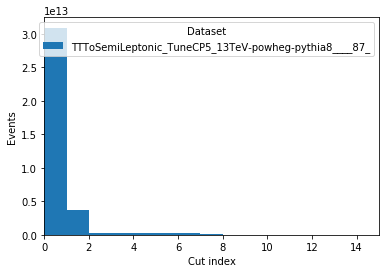

In [4]:
hist.plot1d(output['cutflow'].integrate('region', 'wjete'), overlay='dataset',stack=True)


In [36]:
scale={}
for d in output['sumw'].identifiers('dataset'):
    scale[d]=output['sumw'].integrate('dataset', d).values(overflow='all')[()][1]
    
scale

{<StringBin (HFb--WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____2_) instance at 0x7f78b96af9b0>: 223557280.0,
 <StringBin (HFc--WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____2_) instance at 0x7f78b96af940>: 223557280.0,
 <StringBin (LF--WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____2_) instance at 0x7f78c987ea58>: 223557280.0}

In [45]:
scale={}
for d in output['sumw'].identifiers('dataset'):
    scale[d]=output['sumw'].integrate('dataset', d).values(overflow='all')[()][1]
for key in output.keys():
    if 'cutflow' not in key: continue
    for d in output[key].identifiers('dataset'):
        if 'MET' in d.name or 'SingleElectron' in d.name or 'SinglePhoton' in d.name or 'EGamma' in d.name or 'SingleMuon' in d.name: continue
        output[key].scale({d:1/scale[d]},axis='dataset')

/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/mplhep/_deprecate.py:54: DeprecationWarning: kwarg "densitymode" in function ``histplot`` is deprecated and may be removed in future versions: "unit"mode is not useful
  return func(*args, **kwargs)


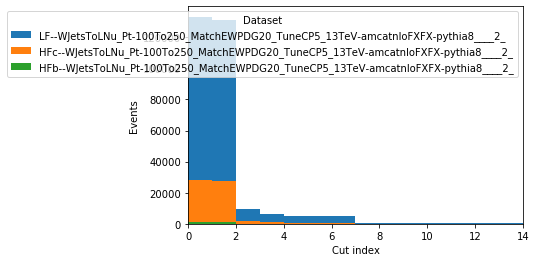

In [87]:
hist.plot1d(output['cutflow'].integrate('region', 'wjete'), overlay='dataset',stack=True)


In [46]:
output['cutflow'].integrate('region', 'wjete').integrate('dataset').values()[()]

array([29038.93964547,  4577.13358814,  4064.01903874,  4063.06851842,
        3805.42607385,  3735.71063456,  3607.56770577,  2106.88577461,
         359.13980777,   306.33929285,   306.33929285,   306.33929285,
         306.33929285,    74.79438584,     0.        ])

In [47]:
output['cutflow'].integrate('region', 'wjete').integrate('dataset').values()[()].sum()

56658.042344586494

In [48]:
output['cutflow'].integrate('region', 'wjete').integrate('dataset').values()

{(): array([29038.93964547,  4577.13358814,  4064.01903874,  4063.06851842,
         3805.42607385,  3735.71063456,  3607.56770577,  2106.88577461,
          359.13980777,   306.33929285,   306.33929285,   306.33929285,
          306.33929285,    74.79438584,     0.        ])}

In [49]:
arr = output['cutflow'].integrate('region', 'wjete').integrate('dataset').values()[()]
dct = {}
dct['wjete']= ['no_cut','isoneE', 'zero_medium_btags', 'met_filters', 'single_electron_triggers', 'atleast_one_jet_with_pt_grt_50', 'Delta_Phi_Met_LJ', 'mt_wjete>50', 'met100', 'noHEMmet', 'exclude_dyjets_less_400', 'exclude_dyjets_greater_400', 'exclude_wjets_less_200', 'exclude_wjets_greater_200']

In [50]:
# print("total events=133026")
for cut, num_events in zip(dct['wjete'], arr):
    print(cut, ':', num_events,'\n')
#     print('----------------------------')

no_cut : 29038.939645469887 

isoneE : 4577.133588141778 

zero_medium_btags : 4064.0190387371485 

met_filters : 4063.0685184236772 

single_electron_triggers : 3805.426073845515 

atleast_one_jet_with_pt_grt_50 : 3735.710634562852 

Delta_Phi_Met_LJ : 3607.5677057740813 

mt_wjete>50 : 2106.885774613872 

met100 : 359.1398077688021 

noHEMmet : 306.33929285259677 

exclude_dyjets_less_400 : 306.33929285259677 

exclude_dyjets_greater_400 : 306.33929285259677 

exclude_wjets_less_200 : 306.33929285259677 

exclude_wjets_greater_200 : 74.79438583850853 



In [22]:
arr

array([133026.,  19936.,  17649.,  17645.,  16532.,  16222.,  15656.,
         9180.,   1574.,   1355.,   1355.,   1355.,   1355.,    309.,
            0.])

In [46]:
vcut=np.ones(10, dtype=np.int)


In [47]:
vcut

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [51]:
(3)*vcut

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3])